Preparing Data

In [3]:
import pandas as pd 

df=pd.read_csv('train.csv')

print(df.shape)
print(df.info())
print(df['SalePrice'].describe())

(2051, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2051 entries, 0 to 2050
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               2051 non-null   int64  
 1   PID              2051 non-null   int64  
 2   MS SubClass      2051 non-null   int64  
 3   MS Zoning        2051 non-null   object 
 4   Lot Frontage     1721 non-null   float64
 5   Lot Area         2051 non-null   int64  
 6   Street           2051 non-null   object 
 7   Alley            140 non-null    object 
 8   Lot Shape        2051 non-null   object 
 9   Land Contour     2051 non-null   object 
 10  Utilities        2051 non-null   object 
 11  Lot Config       2051 non-null   object 
 12  Land Slope       2051 non-null   object 
 13  Neighborhood     2051 non-null   object 
 14  Condition 1      2051 non-null   object 
 15  Condition 2      2051 non-null   object 
 16  Bldg Type        2051 non-null   object 
 17  Hou

In [4]:
cols = [
    'Mas Vnr Type',
    'Fireplace Qu',
    'Garage Type',
    'Garage Finish',
    'Garage Qual',
    'Garage Cond',
    'Bsmt Qual',
    'Bsmt Cond',
    'Bsmt Exposure',
    'BsmtFin Type 1',
    'BsmtFin Type 2'
]

df[cols] = df[cols].fillna('None')

In [5]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [6]:
print(df.isnull().sum().sum())

7590


In [7]:
cat_cols = df.select_dtypes(include=['object']).columns

print(cat_cols)
print("تعداد ستون‌های متنی:", len(cat_cols))

Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type'],
      dtype='object')
تعداد ستون‌های متنی: 42


In [8]:
df = pd.get_dummies(df, columns=cat_cols, dtype=int)

In [9]:
print(df.shape)
print(df.dtypes.value_counts())

(2051, 302)
int32      263
int64       28
float64     11
Name: count, dtype: int64


                Train Test Split


In [10]:
X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

print(X.shape)
print(y.shape)

(2051, 301)
(2051,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(1640, 301)
(411, 301)


            Building Random Forsest Model

In [12]:
from sklearn.ensemble import RandomForestRegressor 

rf=RandomForestRegressor()

rf.fit(X_train,y_train)

RandomForestRegressor()

In [13]:
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))

print("MAE:", mean_absolute_error(y_test, y_test_pred))

rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
print("RMSE:", rmse)

Train R2: 0.9835080918769443
Test R2: 0.909908591896637
MAE: 15190.850243309003
RMSE: 23136.108080450384


            Comparison

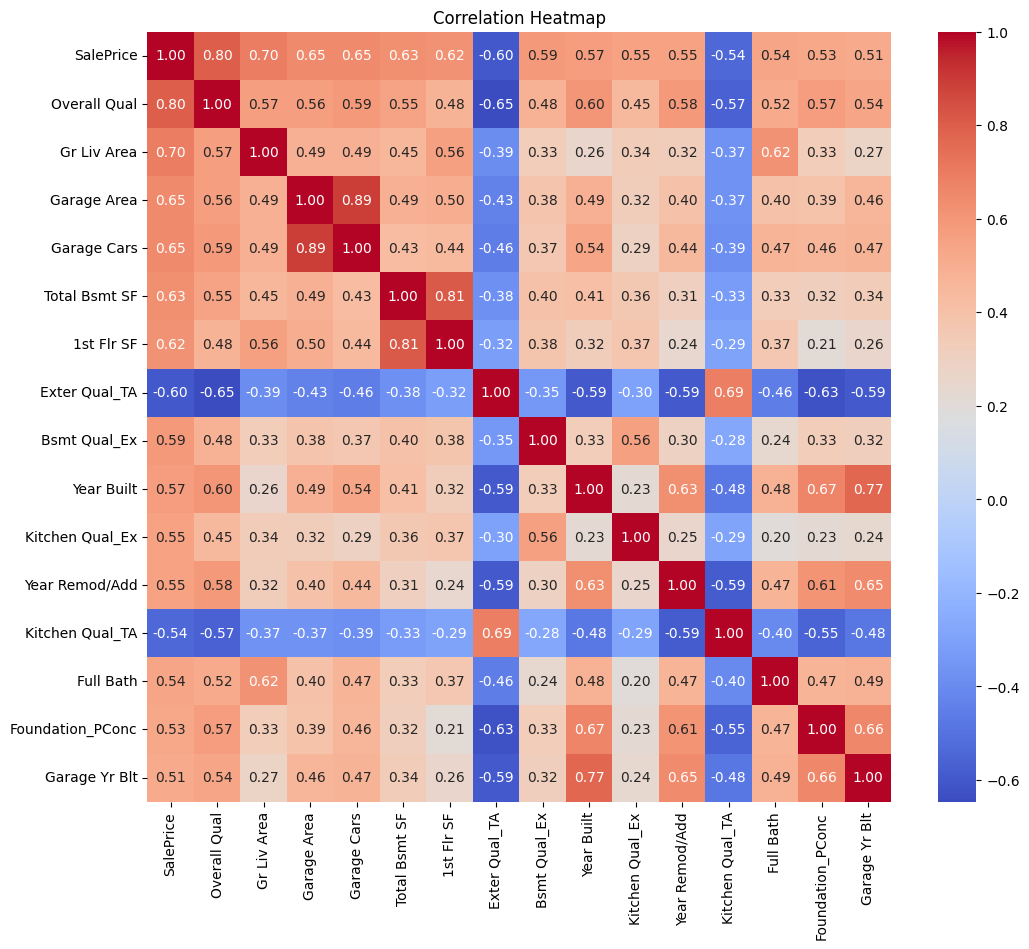

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)['SalePrice']

top_features = corr.abs().sort_values(ascending=False).head(16).index

plt.figure(figsize=(12, 10))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [16]:
import pandas as pd

# همبستگی ویژگی‌ها با قیمت
correlation = df.corr(numeric_only=True)['SalePrice'].drop('SalePrice')

# اهمیت ویژگی‌ها در Random Forest
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

# ساخت جدول مقایسه
comparison = pd.DataFrame({
    'Correlation': correlation,
    'Feature Importance': importance
})

comparison['Abs Correlation'] = comparison['Correlation'].abs()

comparison = comparison.sort_values(
    by='Feature Importance',
    ascending=False
)

print(comparison.head(15))

                 Correlation  Feature Importance  Abs Correlation
Overall Qual        0.800207            0.595445         0.800207
Gr Liv Area         0.697038            0.116526         0.697038
1st Flr SF          0.618486            0.034688         0.618486
Total Bsmt SF       0.628754            0.026798         0.628754
Lot Area            0.296566            0.025838         0.296566
Year Built          0.571849            0.021435         0.571849
BsmtFin SF 1        0.423445            0.020526         0.423445
Garage Area         0.650241            0.011030         0.650241
Year Remod/Add      0.550370            0.009410         0.550370
Kitchen Qual_Ex     0.551284            0.009389         0.551284
PID                -0.255052            0.009323         0.255052
Mas Vnr Area        0.503579            0.008878         0.503579
Garage Cars         0.648128            0.007897         0.648128
Lot Frontage        0.325129            0.006250         0.325129
Full Bath 

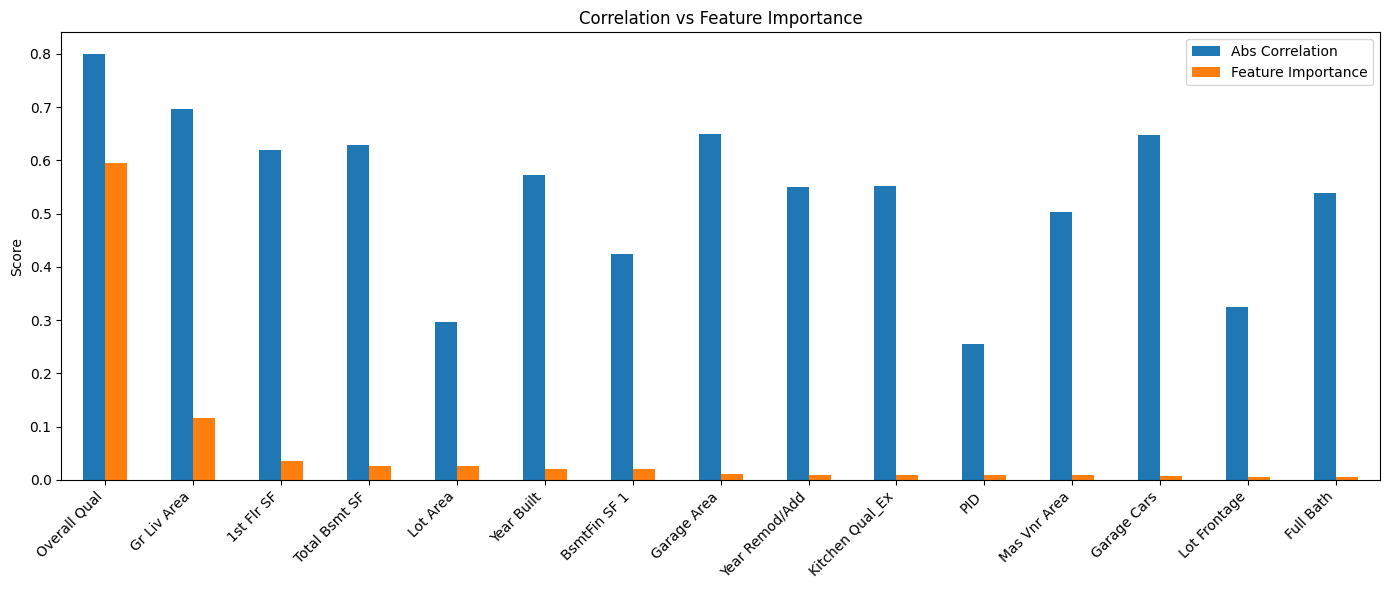

In [17]:
comparison.head(15)[
    ['Abs Correlation', 'Feature Importance']
].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Correlation vs Feature Importance')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [18]:
# انتخاب 15 ویژگی مهم
top_15 = importance.sort_values(ascending=False).head(15).index

X_selected = X[top_15]

# تقسیم داده
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_selected,
    y,
    test_size=0.2,
    random_state=42
)

# ساخت مدل جدید
rf_new = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_new.fit(X_train_new, y_train_new)

# پیش‌بینی
pred = rf_new.predict(X_test_new)

# ارزیابی
print("R2:", r2_score(y_test_new, pred))
print("MAE:", mean_absolute_error(y_test_new, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_new, pred)))

R2: 0.898546662002653
MAE: 16072.105182481753
RMSE: 24551.712356078144


            saving model

In [19]:
import joblib

joblib.dump(rf, 'house_price_model.pkl')

['house_price_model.pkl']

In [20]:
df_raw = pd.read_csv('train.csv')

print(df_raw.shape)
print(df_raw.select_dtypes(include=['object']).columns.tolist())

(2051, 81)
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature', 'Sale Type']


In [21]:
X_raw = df_raw.drop(columns=['SalePrice', 'Id', 'PID'])
y_raw = df_raw['SalePrice']

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [23]:
from sklearn.ensemble import RandomForestRegressor

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    random_state=42
)

model_pipeline.fit(X_train, y_train)

ValueError: A given column is not a column of the dataframe

In [25]:
print("X_train columns:")
print(X_train.columns.tolist()[:10])

print("\nNumeric columns:")
print(num_cols[:10].tolist())

print("\nCategorical columns:")
print(cat_cols[:10].tolist())

print("\nShape:", X_train.shape)

X_train columns:
['MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config']

Numeric columns:
['Id', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area']

Categorical columns:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1']

Shape: (1640, 78)


In [26]:
expected_cols = set(num_cols) | set(cat_cols)
actual_cols = set(X_train.columns)

print("Missing columns:", expected_cols - actual_cols)
print("Extra columns:", actual_cols - expected_cols)

Missing columns: {'SalePrice', 'Id', 'PID'}
Extra columns: set()


In [38]:
# شناسایی مجدد ستون‌ها
num_cols = X_raw.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_cols = X_raw.select_dtypes(
    include=['object']
).columns.tolist()

In [39]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='None'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [40]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [41]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['MS SubClass',
                                                   'Lot Frontage', 'Lot Area',
                                                   'Overall Qual',
                                                   'Overall Cond', 'Year Built',
                                                   'Year Remod/Add',
                                                   'Mas Vnr Area',
                                                   'BsmtFin SF 1',
                                                   'BsmtFin SF 2',
                                                   'Bsmt Unf SF',
                                                   'Total Bsmt SF',
                                                   '1st Flr SF', '2nd Flr SF',
                                                   'Low Qual Fin SF',
                                                   'Gr Liv Area',
                                                   'Bsmt Ful...
                                                   'Condition 1', 'Condition 2',
                                                   'Bldg Type', 'House Style',
                                                   'Roof Style', 'Roof Matl',
                                                   'Exterior 1st',
                                                   'Exterior 2nd',
                                                   'Mas Vnr Type', 'Exter Qual',
                                                   'Exter Cond', 'Foundation',
                                                   'Bsmt Qual', 'Bsmt Cond',
                                                   'Bsmt Exposure',
                                                   'BsmtFin Type 1',
                                                   'BsmtFin Type 2', 'Heating',
                                                   'Heating QC', 'Central Air',
                                                   'Electrical', ...])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [42]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

y_pred = model_pipeline.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.9100512103268569
MAE: 15122.115669099754
RMSE: 23117.78811862024


            saving pipe line 

In [43]:
import joblib

joblib.dump(model_pipeline, 'house_price_pipeline.pkl')

['house_price_pipeline.pkl']

In [44]:
import joblib
import pandas as pd

schema = {}

for col in X_train.columns:

    if X_train[col].dtype == 'object':

        options = sorted(
            X_train[col].dropna().unique().tolist()
        )

        schema[col] = {
            'type': 'categorical',
            'options': options
        }

    else:

        schema[col] = {
            'type': 'numeric',
            'default': float(X_train[col].median())
        }

joblib.dump(schema, 'input_schema.pkl')

print("Schema saved successfully!")
print("Total features:", len(schema))

Schema saved successfully!
Total features: 78
